In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import train_test_split

# Supervised models
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Neural network
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy

# Unsupervised model
from sklearn.cluster import KMeans

# Evaluation metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

np.random.seed(42)
tf.random.set_seed(42)
sns.set_style('whitegrid')

In [ ]:
df = pd.read_csv('software_quality_dataset.csv')
df

,Lines_of_Code,Cyclomatic_Complexity,Num_Functions,Code_Churn,Comment_Density,Num_Bugs,Has_Unit_Tests,Code_Owner_Experience,Quality_Label
0,356.0,31,144,69.567047,0.467561,2,Yes,4,Medium
1,227.0,15,104,131.844422,0.795643,2,No,5,High
2,9674.0,47,141,118.729027,0.316839,5,No,1,High
3,6967.0,42,107,194.397155,0.971883,5,Yes,3,Low
4,7954.0,35,114,69.202293,0.559417,1,No,8,Medium
...,...,...,...,...,...,...,...,...,...
1595,8883.0,40,31,54.863010,0.928920,3,Yes,8,Low
1596,2175.0,44,25,160.802073,0.696037,3,No,1,Low
1597,7872.0,39,47,121.382316,0.461773,3,No,2,High
1598,9660.0,24,55,75.626324,0.999547,2,No,6,Low


In [ ]:
print('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(
    df.shape, df.shape[0], df.shape[1]))

Shape of the dataset is (1600, 9). This dataset contains 1600 rows and 9 columns.


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Lines_of_Code          1520 non-null   float64
 1   Cyclomatic_Complexity  1600 non-null   int64  
 2   Num_Functions          1600 non-null   int64  
 3   Code_Churn             1520 non-null   float64
 4   Comment_Density        1520 non-null   float64
 5   Num_Bugs               1600 non-null   int64  
 6   Has_Unit_Tests         1600 non-null   object 
 7   Code_Owner_Experience  1600 non-null   int64  
 8   Quality_Label          1600 non-null   object 
dtypes: float64(3), int64(4), object(2)
memory usage: 112.6+ KB


In [ ]:
numerical_data = df.select_dtypes(include='number')
numerical_features = numerical_data.columns.tolist()
print(f'There are {len(numerical_features)} numerical features:', '\n')
print(numerical_features)

There are 7 numerical features: 

['Lines_of_Code', 'Cyclomatic_Complexity', 'Num_Functions', 'Code_Churn', 'Comment_Density', 'Num_Bugs', 'Code_Owner_Experience']


In [ ]:
categorical_data = df.select_dtypes(include='object')
categorical_features = categorical_data.columns.tolist()
print(f'There are {len(categorical_features)} categorical features:', '\n')
print(categorical_features)

There are 2 categorical features: 

['Has_Unit_Tests', 'Quality_Label']


In [ ]:
numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Lines_of_Code,1520.0,4939.269737,2867.248259,106.000000,2490.750000,4860.000000,7455.250000,9998.000000
Cyclomatic_Complexity,1600.0,25.076875,13.879621,1.000000,13.000000,25.000000,37.000000,49.000000
Num_Functions,1600.0,103.178125,55.503710,5.000000,56.000000,104.000000,152.000000,199.000000
Code_Churn,1520.0,102.572291,50.546329,-64.283310,67.509852,104.007452,138.619113,295.139936
Comment_Density,1520.0,0.549370,0.256137,0.101037,0.337596,0.542108,0.765766,0.999976
Num_Bugs,1600.0,2.934375,1.715928,0.000000,2.000000,3.000000,4.000000,10.000000
Code_Owner_Experience,1600.0,5.045000,2.559701,1.000000,3.000000,5.000000,7.000000,9.000000


In [ ]:
categorical_data.describe().T

,count,unique,top,freq
Has_Unit_Tests,1600,2,No,820
Quality_Label,1600,3,High,566


In [ ]:
df.nunique()

,0
Lines_of_Code,1413
Cyclomatic_Complexity,49
Num_Functions,195
Code_Churn,1520
Comment_Density,1520
Num_Bugs,11
Has_Unit_Tests,2
Code_Owner_Experience,9
Quality_Label,3


In [ ]:
print('Number of duplicated rows:', df.duplicated().sum())

Number of duplicated rows: 0


In [ ]:
numerical_data.var()

,0
Lines_of_Code,8.221113e+06
Cyclomatic_Complexity,1.926439e+02
Num_Functions,3.080662e+03
Code_Churn,2.554931e+03
Comment_Density,6.560604e-02
Num_Bugs,2.944409e+00
Code_Owner_Experience,6.552070e+00


In [ ]:
numerical_data.skew()

,0
Lines_of_Code,0.055175
Cyclomatic_Complexity,0.015461
Num_Functions,-0.034194
Code_Churn,-0.113186
Comment_Density,0.004302
Num_Bugs,0.667812
Code_Owner_Experience,-0.042283


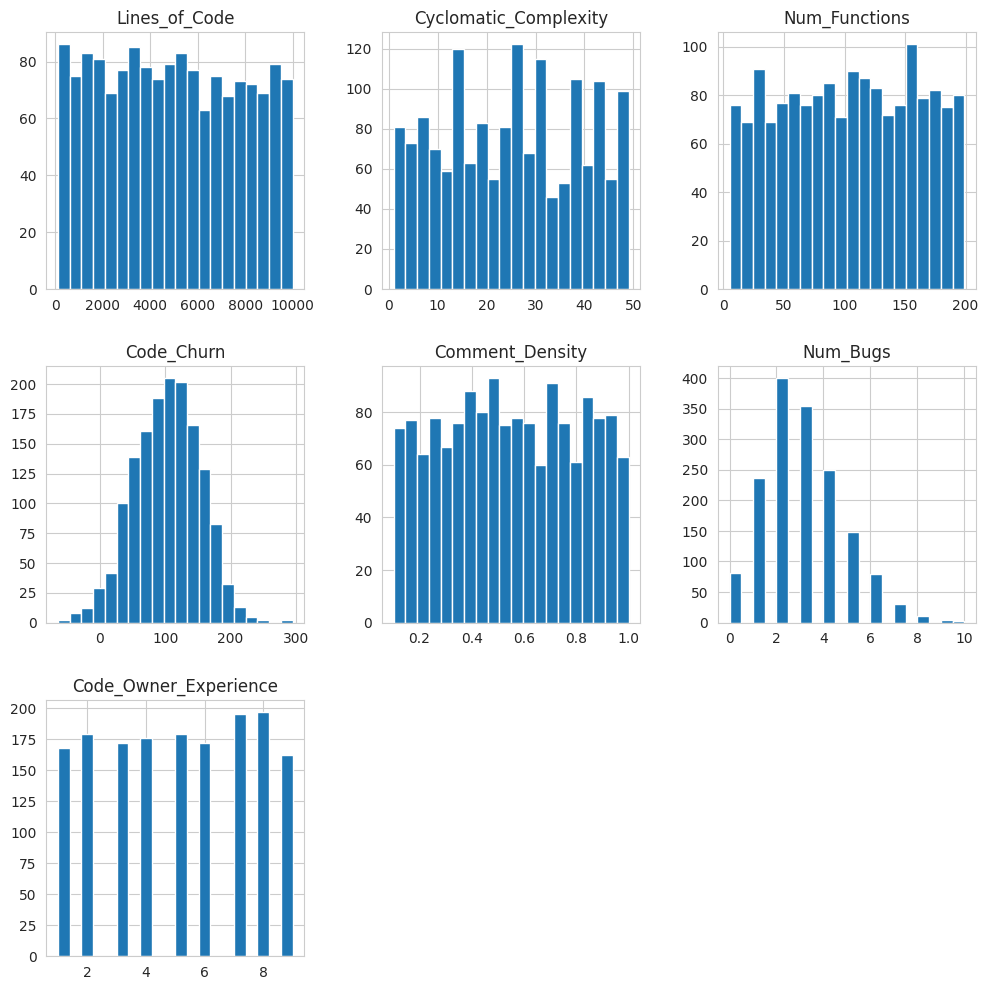

In [ ]:
numerical_data.hist(figsize=(12, 12), bins=20)
plt.show()

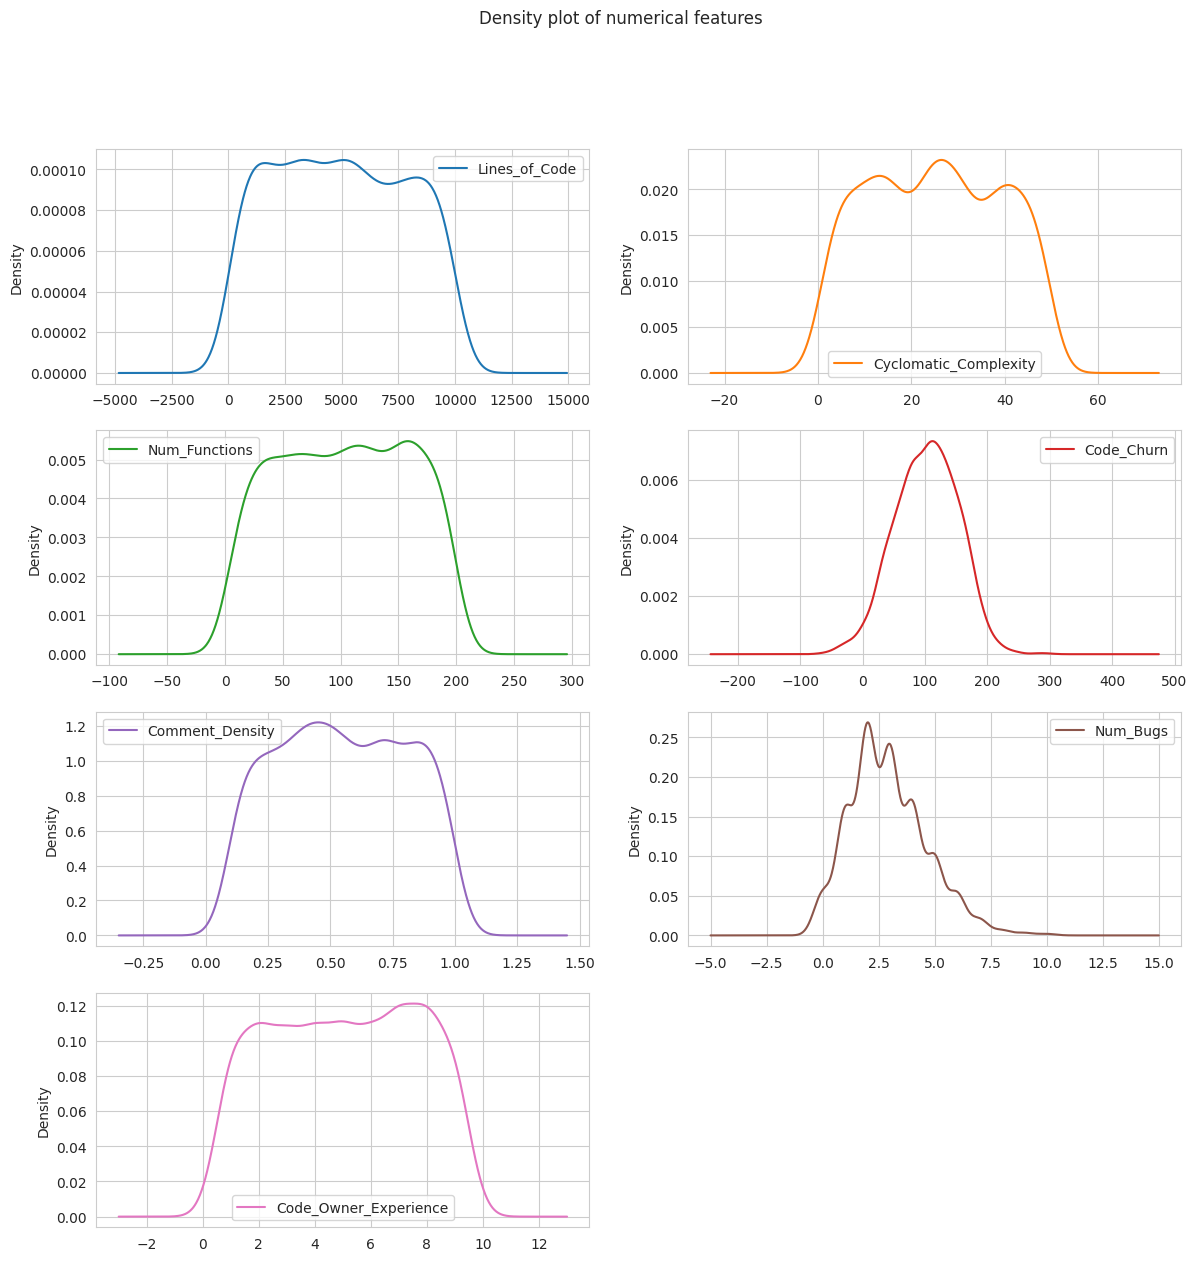

In [ ]:
numerical_data.plot(kind='density', figsize=(14, 14), subplots=True, layout=(4, 2),
                    title='Density plot of numerical features', sharex=False)
plt.show()

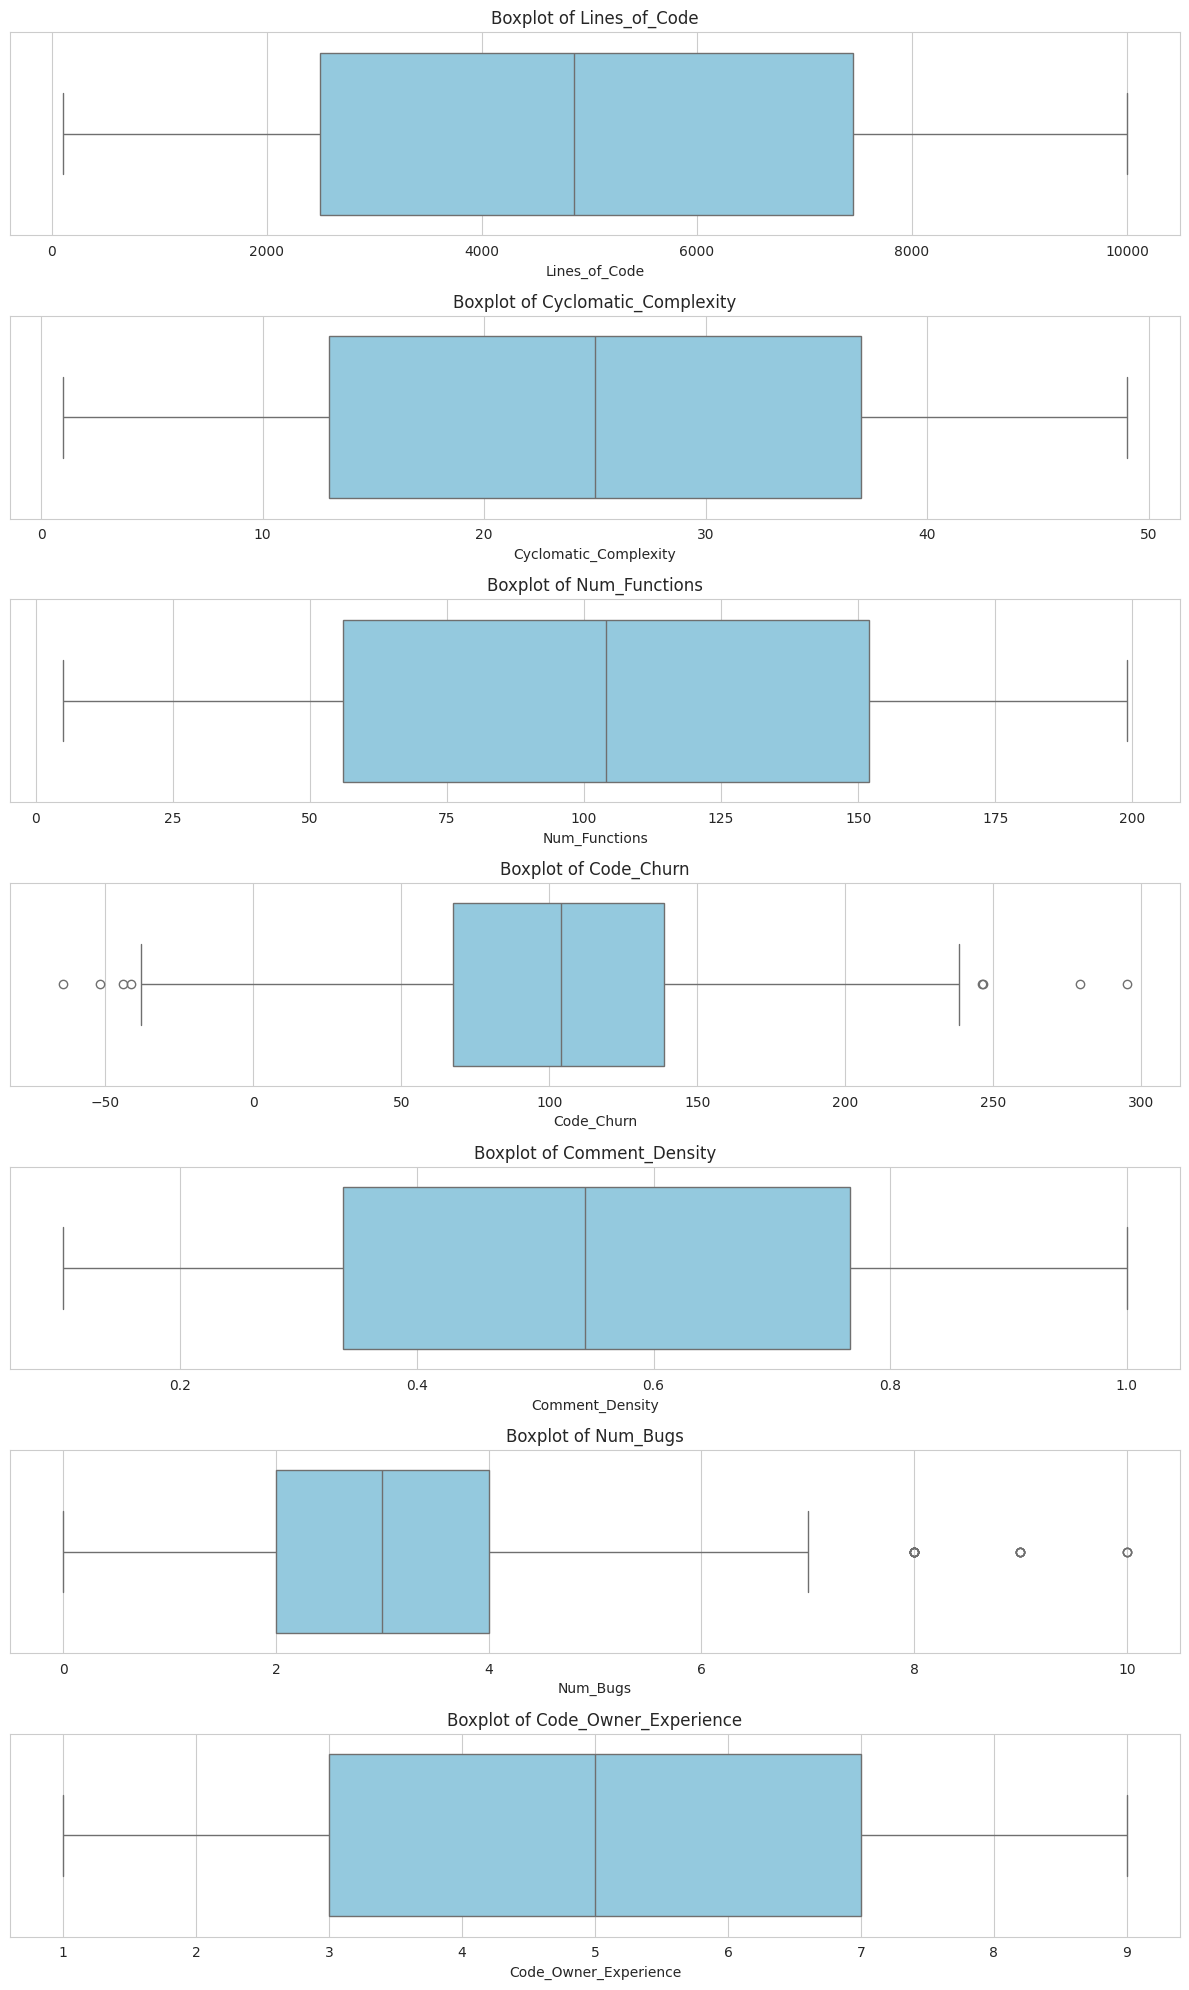

In [ ]:
plt.figure(figsize=(12, 20))
for i, col in enumerate(numerical_features, 1):
    plt.subplot(len(numerical_features), 1, i)
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
plt.tight_layout()
plt.show()

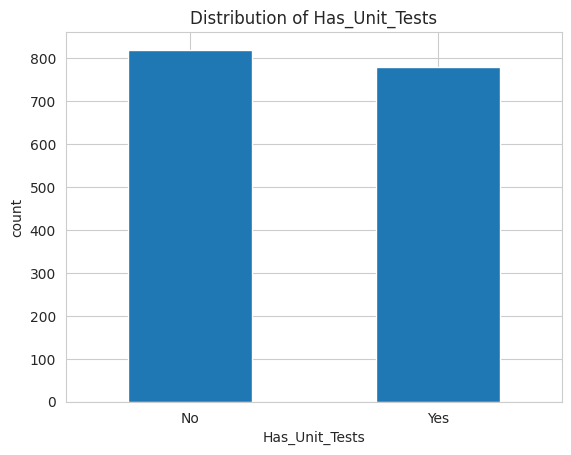

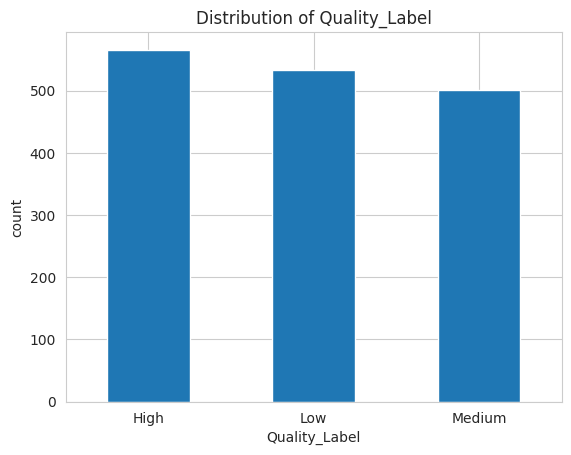

In [ ]:
for col in categorical_features:
    plt.title(f'Distribution of {col}')
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=0,
                                                          xlabel=col, ylabel='count')
    plt.show()

### Correlation of all the features


In [ ]:
# Temporary numeric copy so that the categorical columns can join the correlation test
df_corr = df.copy()
df_corr['Has_Unit_Tests'] = df_corr['Has_Unit_Tests'].map({'No': 0, 'Yes': 1})
df_corr['Quality_Label'] = df_corr['Quality_Label'].map({'Low': 0, 'Medium': 1, 'High': 2})

correlation_matrix = df_corr.corr()
correlation_matrix

,Lines_of_Code,Cyclomatic_Complexity,Num_Functions,Code_Churn,Comment_Density,Num_Bugs,Has_Unit_Tests,Code_Owner_Experience,Quality_Label
Lines_of_Code,1.000000,0.046746,-0.026398,0.003710,0.019014,-0.029780,-0.001311,0.015243,0.013405
Cyclomatic_Complexity,0.046746,1.000000,-0.005937,-0.022347,0.041138,-0.076648,0.031544,-0.019038,-0.008075
Num_Functions,-0.026398,-0.005937,1.000000,-0.005121,-0.002924,0.007963,0.003968,0.011028,-0.001412
Code_Churn,0.003710,-0.022347,-0.005121,1.000000,0.010962,-0.015592,0.037555,0.022090,-0.002579
Comment_Density,0.019014,0.041138,-0.002924,0.010962,1.000000,-0.045190,-0.006944,0.028216,-0.028832
Num_Bugs,-0.029780,-0.076648,0.007963,-0.015592,-0.045190,1.000000,0.013257,-0.008013,0.005350
Has_Unit_Tests,-0.001311,0.031544,0.003968,0.037555,-0.006944,0.013257,1.000000,0.003860,0.034579
Code_Owner_Experience,0.015243,-0.019038,0.011028,0.022090,0.028216,-0.008013,0.003860,1.000000,-0.032571
Quality_Label,0.013405,-0.008075,-0.001412,-0.002579,-0.028832,0.005350,0.034579,-0.032571,1.000000


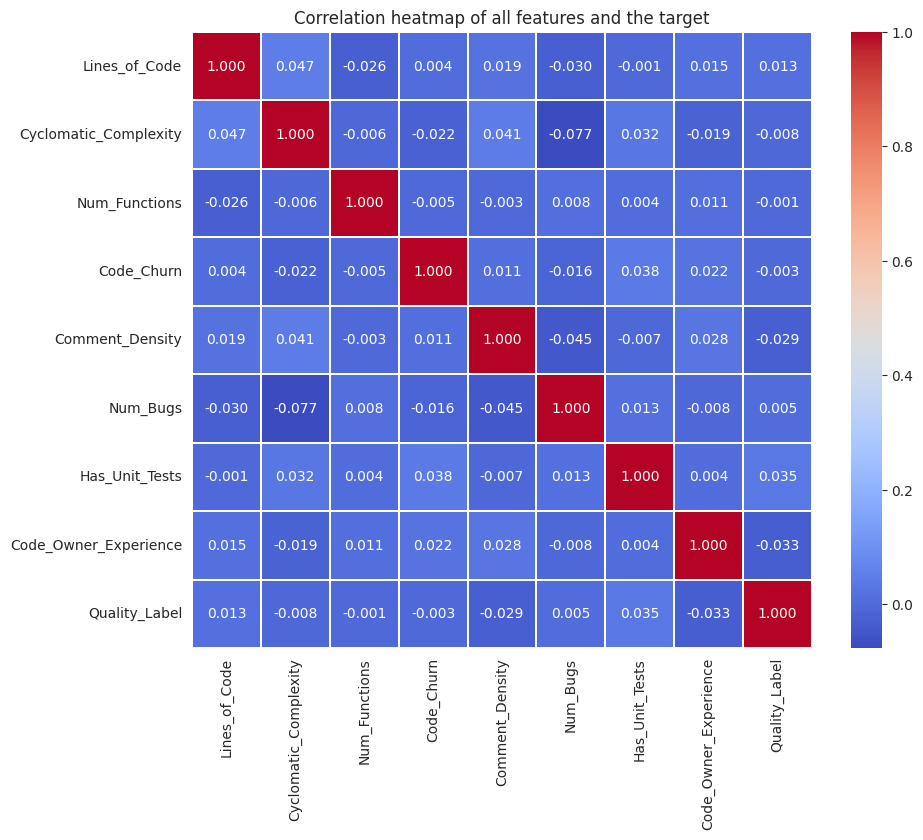

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.3)
plt.title('Correlation heatmap of all features and the target')
plt.show()

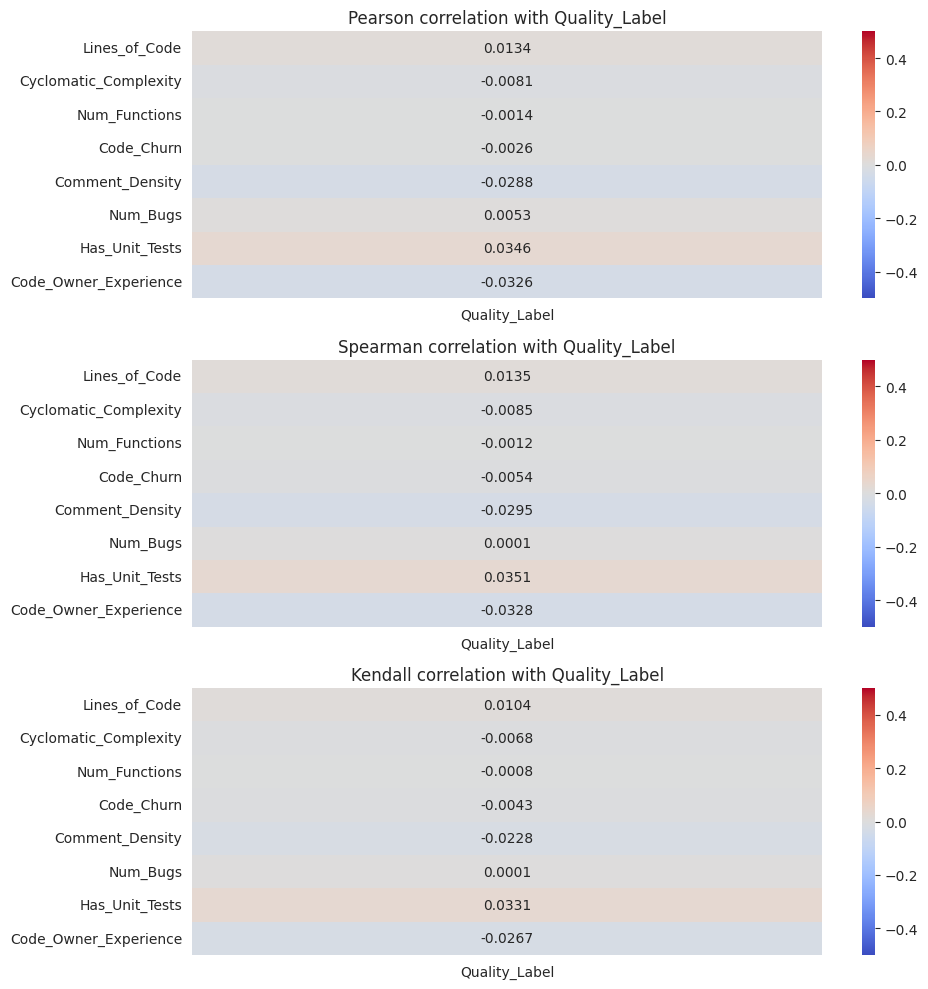

In [ ]:
fig, ax = plt.subplots(3, 1, figsize=(10, 10))

for i, method in enumerate(['pearson', 'spearman', 'kendall']):
    corr_target = df_corr.corr(method=method)[['Quality_Label']].drop('Quality_Label')
    sns.heatmap(corr_target, annot=True, cmap='coolwarm', fmt='.4f', vmin=-0.5, vmax=0.5, ax=ax[i])
    ax[i].set_title(f'{method.capitalize()} correlation with Quality_Label')

plt.tight_layout()
plt.show()

### Imbalanced dataset check


In [ ]:
class_counts = df.groupby('Quality_Label').size()
print(class_counts)

imbalance_df = pd.DataFrame({'outcome': class_counts.index,
                             'count': class_counts.values,
                             'percentage': (class_counts.values / len(df) * 100).round(2)})
imbalance_df

Quality_Label
High      566
Low       533
Medium    501
dtype: int64


,outcome,count,percentage
0,High,566,35.38
1,Low,533,33.31
2,Medium,501,31.31


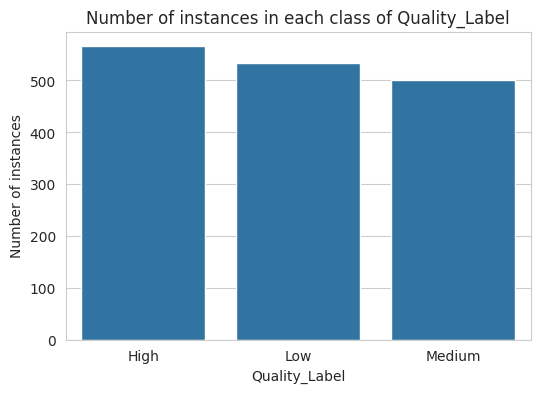

In [ ]:
plt.figure(figsize=(6, 4))
sns.barplot(data=imbalance_df, x='outcome', y='count')
plt.title('Number of instances in each class of Quality_Label')
plt.xlabel('Quality_Label')
plt.ylabel('Number of instances')
plt.show()

# 3. Dataset pre-processing


### Problem 1 — Null / missing values

In [ ]:
# Check for null values
df.isnull().sum()

,0
Lines_of_Code,80
Cyclomatic_Complexity,0
Num_Functions,0
Code_Churn,80
Comment_Density,80
Num_Bugs,0
Has_Unit_Tests,0
Code_Owner_Experience,0
Quality_Label,0


In [ ]:
# What percentage of each column is missing?
(df.isnull().sum() / len(df) * 100).round(2)

,0
Lines_of_Code,5.0
Cyclomatic_Complexity,0.0
Num_Functions,0.0
Code_Churn,5.0
Comment_Density,5.0
Num_Bugs,0.0
Has_Unit_Tests,0.0
Code_Owner_Experience,0.0
Quality_Label,0.0


In [ ]:
# Impute the three columns that have missing values, using the median
impute = SimpleImputer(missing_values=np.nan, strategy='median')

for col in ['Lines_of_Code', 'Code_Churn', 'Comment_Density']:
    impute.fit(df[[col]])
    df[col] = impute.transform(df[[col]])
    print(f'{col}: filled with median = {round(impute.statistics_[0], 4)}')

Lines_of_Code: filled with median = 4860.0
Code_Churn: filled with median = 104.0075
Comment_Density: filled with median = 0.5421


In [ ]:
# Confirm that there are no null values left
df.isnull().sum()

,0
Lines_of_Code,0
Cyclomatic_Complexity,0
Num_Functions,0
Code_Churn,0
Comment_Density,0
Num_Bugs,0
Has_Unit_Tests,0
Code_Owner_Experience,0
Quality_Label,0


### Problem 2 — Categorical values

In [ ]:
# Encode the binary categorical feature
enc = LabelEncoder()
df['Has_Unit_Tests'] = enc.fit_transform(df['Has_Unit_Tests'])
print('Has_Unit_Tests encoding:', dict(zip(enc.classes_, enc.transform(enc.classes_))))

Has_Unit_Tests encoding: {'No': np.int64(0), 'Yes': np.int64(1)}


In [ ]:
# Encode the target
label_encoder = LabelEncoder()
df['Quality_Label'] = label_encoder.fit_transform(df['Quality_Label'])
class_names = label_encoder.classes_
print('Quality_Label encoding:', dict(zip(class_names, label_encoder.transform(class_names))))

Quality_Label encoding: {'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}


In [ ]:
df.head(10)

,Lines_of_Code,Cyclomatic_Complexity,Num_Functions,Code_Churn,Comment_Density,Num_Bugs,Has_Unit_Tests,Code_Owner_Experience,Quality_Label
0,356.0,31,144,69.567047,0.467561,2,1,4,2
1,227.0,15,104,131.844422,0.795643,2,0,5,0
2,9674.0,47,141,118.729027,0.316839,5,0,1,0
3,6967.0,42,107,194.397155,0.971883,5,1,3,1
4,7954.0,35,114,69.202293,0.559417,1,0,8,2
5,2305.0,38,120,164.299559,0.353860,5,0,6,2
6,8613.0,22,26,54.968552,0.355856,5,1,3,2
7,4479.0,5,149,88.060247,0.116470,7,1,7,0
8,8167.0,48,165,68.074588,0.723188,1,1,6,1
9,6377.0,13,179,75.227914,0.798353,5,1,5,2


---
# 4. Dataset splitting

In [ ]:
X = df.drop('Quality_Label', axis=1)
y = df['Quality_Label']

print('Shape of X:', X.shape)
print('Shape of y:', y.shape)

Shape of X: (1600, 8)
Shape of y: (1600,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Training set:', X_train.shape[0], 'rows')
print('Testing set :', X_test.shape[0], 'rows')

Training set: 1280 rows
Testing set : 320 rows


### Problem 3 — Feature scaling

In [ ]:
# Apply feature scaling - fit on the training set only, then transform both sets
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

---
# 5. Model training and testing

We train three supervised models — a Decision Tree, a K-Nearest Neighbors classifier and a Neural
Network — and then treat the same data as an unsupervised problem with K-means in Section 7.

Throughout this section, remember the baseline established in the EDA: because there are three
roughly equal classes, a model that guesses at random scores about **33.3 %**. Any model must beat
that number to be doing anything useful.

## 5.1 Model 1 — Decision Tree Classifier

A Decision Tree repeatedly splits the data on the feature and threshold that give the purest
children, measured here with the Gini impurity. We set `max_depth=5` to stop the tree from growing
until every leaf holds a single training row; the second cell shows what happens without that limit.
Notice that we fit the tree on the **unscaled** features, because a tree is scale-invariant.

In [ ]:
# Train the Decision Tree
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train, y_train)

# Predict on both sets
y_pred_dt_train = dt.predict(X_train)
y_pred_dt = dt.predict(X_test)

print('Decision Tree training accuracy: {:.2f}%'.format(accuracy_score(y_train, y_pred_dt_train) * 100))
print('Decision Tree testing accuracy : {:.2f}%'.format(accuracy_score(y_test, y_pred_dt) * 100))

Decision Tree training accuracy: 42.27%
Decision Tree testing accuracy : 33.44%


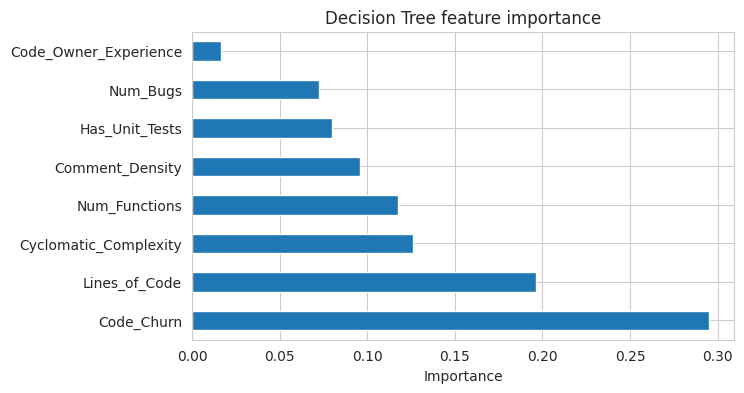

In [ ]:
# Which features did the tree find most useful?
importance = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.plot(kind='barh', figsize=(7, 4))
plt.title('Decision Tree feature importance')
plt.xlabel('Importance')
plt.show()

In [ ]:
# What happens if we let the tree grow without any depth limit?
dt_full = DecisionTreeClassifier(random_state=42)
dt_full.fit(X_train, y_train)

print('Unlimited tree depth      :', dt_full.get_depth())
print('Unlimited tree leaf count :', dt_full.get_n_leaves())
print('Unlimited tree training accuracy: {:.2f}%'.format(
    accuracy_score(y_train, dt_full.predict(X_train)) * 100))
print('Unlimited tree testing accuracy : {:.2f}%'.format(
    accuracy_score(y_test, dt_full.predict(X_test)) * 100))

Unlimited tree depth      : 25
Unlimited tree leaf count : 477
Unlimited tree training accuracy: 100.00%
Unlimited tree testing accuracy : 32.19%


## 5.2 Model 2 — K-Nearest Neighbors (KNN)

KNN stores the training set and classifies a new point by the majority vote of its `k` closest
neighbours. It works on the **scaled** features, for the distance reason explained in Section 3.
First we check a range of `k` values, then we fit the final model.

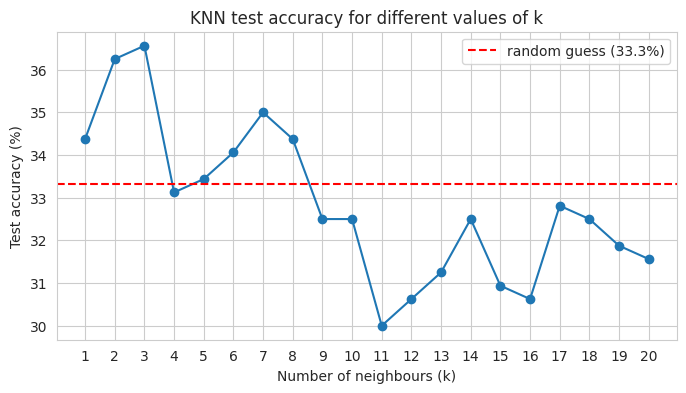

In [ ]:
# Try several values of k and see which one works best
k_values = range(1, 21)
k_scores = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)
    k_scores.append(knn_temp.score(X_test_scaled, y_test) * 100)

plt.figure(figsize=(8, 4))
plt.plot(k_values, k_scores, marker='o')
plt.axhline(100 / 3, linestyle='--', color='red', label='random guess (33.3%)')
plt.xlabel('Number of neighbours (k)')
plt.ylabel('Test accuracy (%)')
plt.title('KNN test accuracy for different values of k')
plt.xticks(list(k_values))
plt.legend()
plt.show()

In [ ]:
# Train the final KNN model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)

print('KNN training accuracy: {:.2f}%'.format(knn.score(X_train_scaled, y_train) * 100))
print('KNN testing accuracy : {:.2f}%'.format(accuracy_score(y_test, y_pred_knn) * 100))

KNN training accuracy: 55.08%
KNN testing accuracy : 33.44%


## 5.3 Model 3 — Neural Network (mandatory)

A fully connected feed-forward network built with Keras. The architecture is
**8 inputs -> 32 ReLU -> 16 ReLU -> 3 softmax**: two hidden layers give it enough capacity to learn
non-linear interactions between the metrics that a tree or KNN might miss, while the softmax output
layer produces a probability for each of the three classes. We compile it with the `Adam` optimiser
at learning rate 0.001 and `SparseCategoricalCrossentropy`, which is the correct loss for integer
class labels. It trains on the **scaled** features, and we hold back 20 % of the training data as a
validation set so the loss curves can reveal overfitting.

In [ ]:
# Create the model
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(3, activation='softmax')
])

# Compile the model
model.compile(optimizer=Adam(0.001),
              loss=SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

In [ ]:
# Train the model
history = model.fit(X_train_scaled, y_train,
                    epochs=50,
                    batch_size=32,
                    validation_split=0.2,
                    verbose=1)

Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.3564 - loss: 1.1245 - val_accuracy: 0.3477 - val_loss: 1.1106
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3662 - loss: 1.0992 - val_accuracy: 0.3516 - val_loss: 1.0983
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3779 - loss: 1.0890 - val_accuracy: 0.3203 - val_loss: 1.0960
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3916 - loss: 1.0825 - val_accuracy: 0.3555 - val_loss: 1.0945
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4102 - loss: 1.0773 - val_accuracy: 0.3633 - val_loss: 1.0938
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.4053 - loss: 1.0732 - val_accuracy: 0.3750 - val_loss: 1.0932
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4199 - loss: 1.0697 - val_accuracy: 0.3828 - val_loss: 1.0928
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4277 - loss: 1.0665 - val_accuracy: 0.3867 - v

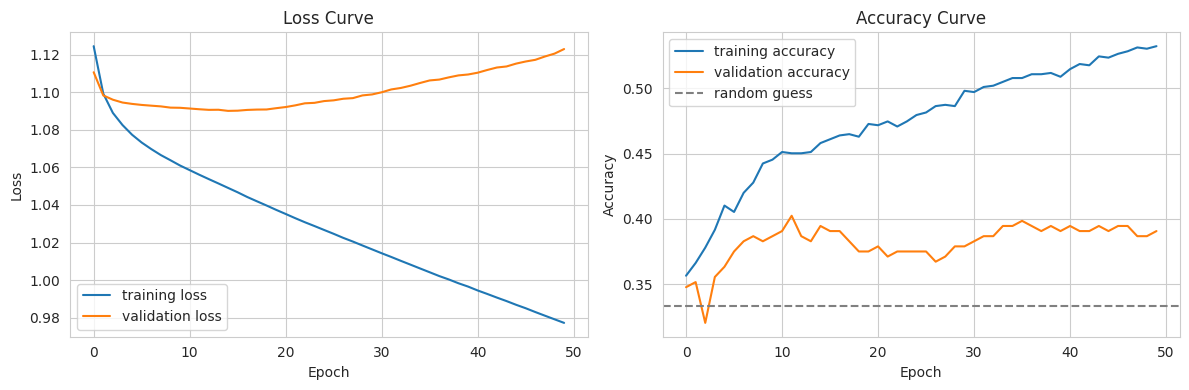

In [ ]:
# Plot the loss curve
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='training loss')
plt.plot(history.history['val_loss'], label='validation loss')
plt.title('Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='training accuracy')
plt.plot(history.history['val_accuracy'], label='validation accuracy')
plt.axhline(1 / 3, linestyle='--', color='grey', label='random guess')
plt.title('Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Evaluate the neural network on the test set
y_pred_nn = model.predict(X_test_scaled).argmax(axis=1)

print('Neural Network training accuracy: {:.2f}%'.format(
    model.evaluate(X_train_scaled, y_train, verbose=0)[1] * 100))
print('Neural Network testing accuracy : {:.2f}%'.format(
    model.evaluate(X_test_scaled, y_test, verbose=0)[1] * 100))

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Neural Network training accuracy: 50.31%
Neural Network testing accuracy : 30.63%


# 6. Model selection / Comparison analysis [supervised models]


In [ ]:
# Collect the predictions and the predicted probabilities(percentages) of every model
predictions = {'Decision Tree': y_pred_dt,
               'KNN (k=5)': y_pred_knn,
               'Neural Network': y_pred_nn}

probabilities = {'Decision Tree': dt.predict_proba(X_test),
                 'KNN (k=5)': knn.predict_proba(X_test_scaled),
                 'Neural Network': model.predict(X_test_scaled, verbose=0)}

In [ ]:
# Build a summary table of all the metrics
rows = []
for name, y_pred in predictions.items():
    rows.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(y_test, y_pred) * 100, 2),
        'Precision (%)': round(precision_score(y_test, y_pred, average='macro',
                                               zero_division=0) * 100, 2),
        'Recall (%)': round(recall_score(y_test, y_pred, average='macro') * 100, 2),
        'F1 score (%)': round(f1_score(y_test, y_pred, average='macro') * 100, 2)
    })

results = pd.DataFrame(rows)
results

,Model,Accuracy (%),Precision (%),Recall (%),F1 score (%)
0,Decision Tree,33.44,22.87,32.24,26.31
1,KNN (k=5),33.44,32.57,32.62,32.43
2,Neural Network,30.63,30.48,30.92,30.44


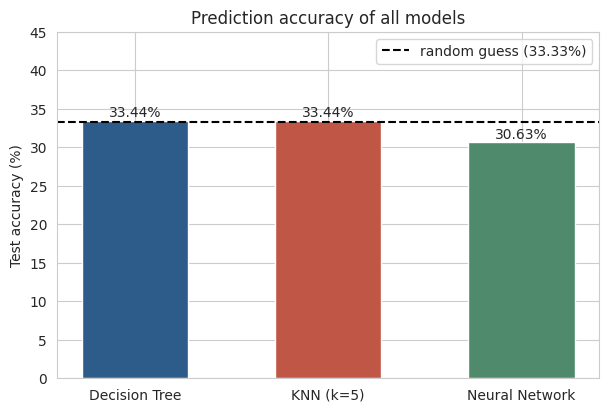

In [ ]:
# Bar chart of the prediction accuracy of all the models
plt.figure(figsize=(7, 4.5))
bars = plt.bar(results['Model'], results['Accuracy (%)'],
               color=['#2E5C8A', '#C05746', '#4E8A6B'], width=0.55)
plt.axhline(100 / 3, linestyle='--', color='black', label='random guess (33.33%)')

for bar, value in zip(bars, results['Accuracy (%)']):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.5, f'{value}%', ha='center')

plt.ylim(0, 45)
plt.ylabel('Test accuracy (%)')
plt.title('Prediction accuracy of all models')
plt.legend()
plt.show()

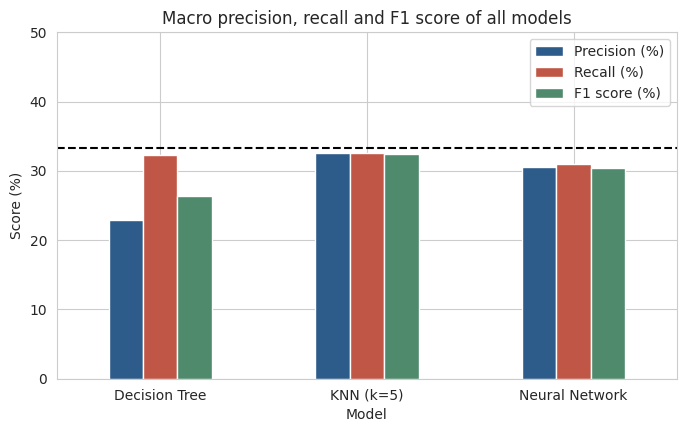

In [ ]:
# Precision and recall comparison
results.plot(x='Model', y=['Precision (%)', 'Recall (%)', 'F1 score (%)'],
             kind='bar', figsize=(8, 4.5), rot=0,
             color=['#2E5C8A', '#C05746', '#4E8A6B'])
plt.axhline(100 / 3, linestyle='--', color='black')
plt.ylabel('Score (%)')
plt.ylim(0, 50)
plt.title('Macro precision, recall and F1 score of all models')
plt.show()

In [ ]:
# Full classification report for every model
for name, y_pred in predictions.items():
    print('=' * 60)
    print(name)
    print('=' * 60)
    print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

Decision Tree
              precision    recall  f1-score   support

        High       0.38      0.40      0.39       127
         Low       0.31      0.57      0.40        99
      Medium       0.00      0.00      0.00        94

    accuracy                           0.33       320
   macro avg       0.23      0.32      0.26       320
weighted avg       0.25      0.33      0.28       320

KNN (k=5)
              precision    recall  f1-score   support

        High       0.37      0.40      0.39       127
         Low       0.32      0.35      0.34        99
      Medium       0.28      0.22      0.25        94

    accuracy                           0.33       320
   macro avg       0.33      0.33      0.32       320
weighted avg       0.33      0.33      0.33       320

Neural Network
              precision    recall  f1-score   support

        High       0.32      0.27      0.29       127
         Low       0.31      0.39      0.35        99
      Medium       0.28      0.27   

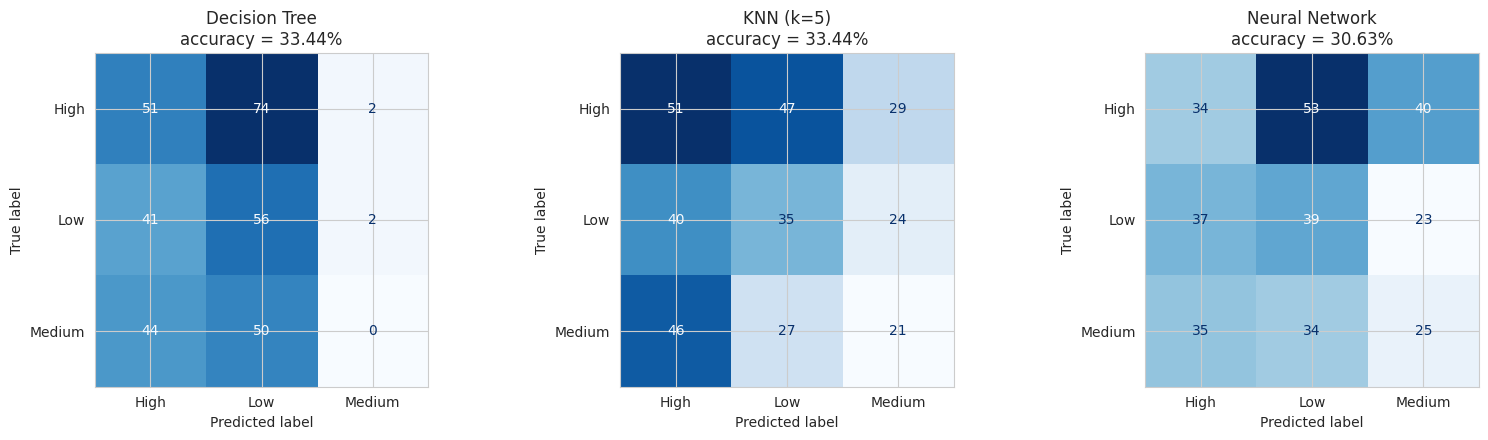

In [ ]:
# Confusion matrix of every model
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

for i, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues', ax=ax[i],
                                                               colorbar=False)
    ax[i].set_title(f'{name}\naccuracy = {accuracy_score(y_test, y_pred) * 100:.2f}%')

plt.tight_layout()
plt.show()

### ROC curve and AUC score

ROC and AUC are defined for two classes, so for a three-class problem we use the
**one-vs-rest** approach: each class in turn becomes the positive class and the other two become the
negative class. `label_binarize` builds those three binary targets. The first chart averages the
three curves for each model (the macro-average ROC) so the models can be compared directly; the
second chart opens the three per-class curves up for each model separately.

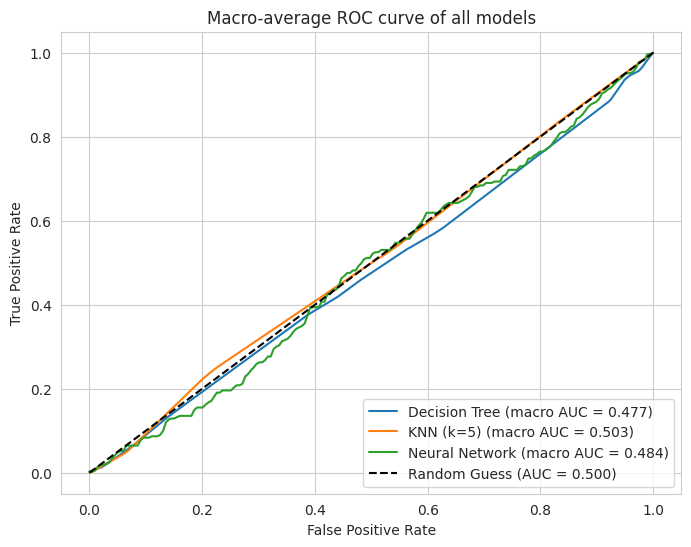

In [ ]:
# Binarize the test labels for the one-vs-rest ROC analysis
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

# Macro-average ROC curve of each model
plt.figure(figsize=(8, 6))
mean_fpr = np.linspace(0, 1, 200)

for name, y_prob in probabilities.items():
    mean_tpr = np.zeros_like(mean_fpr)
    for i in range(3):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
        mean_tpr = mean_tpr + np.interp(mean_fpr, fpr, tpr)
    mean_tpr = mean_tpr / 3
    roc_auc = auc(mean_fpr, mean_tpr)
    plt.plot(mean_fpr, mean_tpr, label=f'{name} (macro AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.500)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Macro-average ROC curve of all models')
plt.legend(loc='lower right')
plt.show()

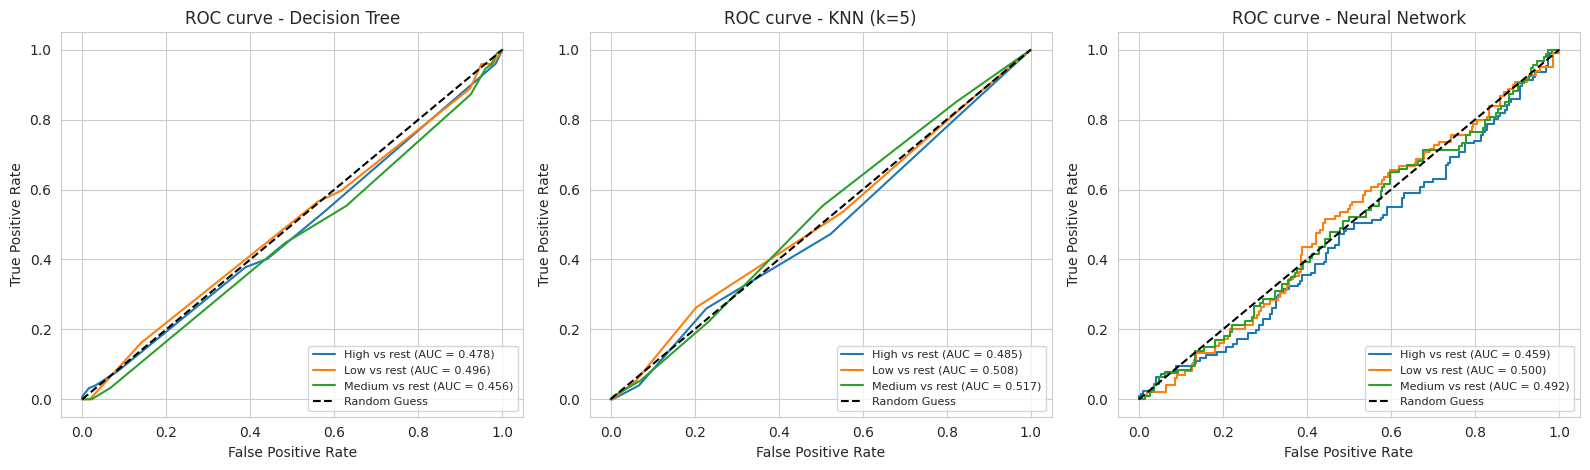

In [ ]:
# Per-class one-vs-rest ROC curve of every model
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))

for j, (name, y_prob) in enumerate(probabilities.items()):
    for i in range(3):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
        ax[j].plot(fpr, tpr, label=f'{class_names[i]} vs rest (AUC = {auc(fpr, tpr):.3f})')
    ax[j].plot([0, 1], [0, 1], 'k--', label='Random Guess')
    ax[j].set_xlabel('False Positive Rate')
    ax[j].set_ylabel('True Positive Rate')
    ax[j].set_title(f'ROC curve - {name}')
    ax[j].legend(loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
# Add the AUC score of every model to the summary table
auc_scores = []
for name, y_prob in probabilities.items():
    mean_tpr = np.zeros_like(mean_fpr)
    for i in range(3):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
        mean_tpr = mean_tpr + np.interp(mean_fpr, fpr, tpr)
    auc_scores.append(round(auc(mean_fpr, mean_tpr / 3), 3))

results['Macro AUC'] = auc_scores
results

,Model,Accuracy (%),Precision (%),Recall (%),F1 score (%),Macro AUC
0,Decision Tree,33.44,22.87,32.24,26.31,0.477
1,KNN (k=5),33.44,32.57,32.62,32.43,0.503
2,Neural Network,30.63,30.48,30.92,30.44,0.484


---
# 7. Unsupervised learning — K-means Clustering

Now we throw the labels away and treat the problem as an unsupervised one. K-means partitions the
data into `K` groups by repeatedly assigning each point to the nearest centroid and then moving each
centroid to the mean of its group. We cluster the **scaled** features, because K-means uses
Euclidean distance for exactly the same reason KNN does.

In [ ]:
# Scale all the features for clustering (the labels are not used at all here)
X_cluster = StandardScaler().fit_transform(X)

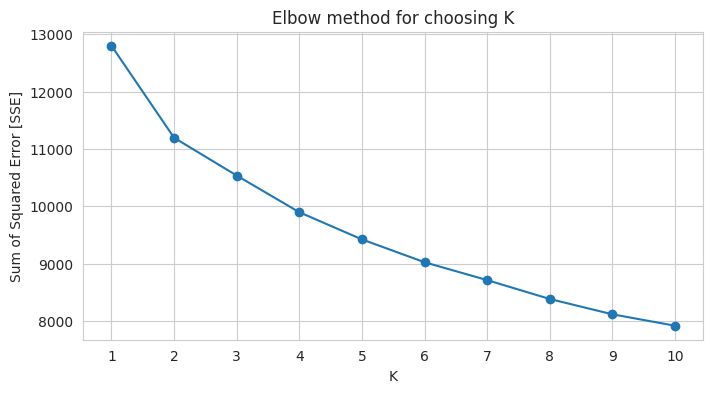

In [ ]:
# Elbow method: find a good number of clusters
k_range = range(1, 11)
SSE = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster)
    SSE.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, SSE, marker='o')
plt.xlabel('K')
plt.ylabel('Sum of Squared Error [SSE]')
plt.title('Elbow method for choosing K')
plt.xticks(list(k_range))
plt.show()

In [ ]:
# Apply K-means with K = 3 (as our wish)
km = KMeans(n_clusters=3, random_state=42, n_init=10)
y_clusters = km.fit_predict(X_cluster)

df['Cluster'] = y_clusters
print('Number of points in each cluster:')
print(df['Cluster'].value_counts().sort_index())
print()
print('Inertia (SSE) at K = 3:', round(km.inertia_, 2))

Number of points in each cluster:
Cluster
0    429
1    392
2    779
Name: count, dtype: int64

Inertia (SSE) at K = 3: 10536.73


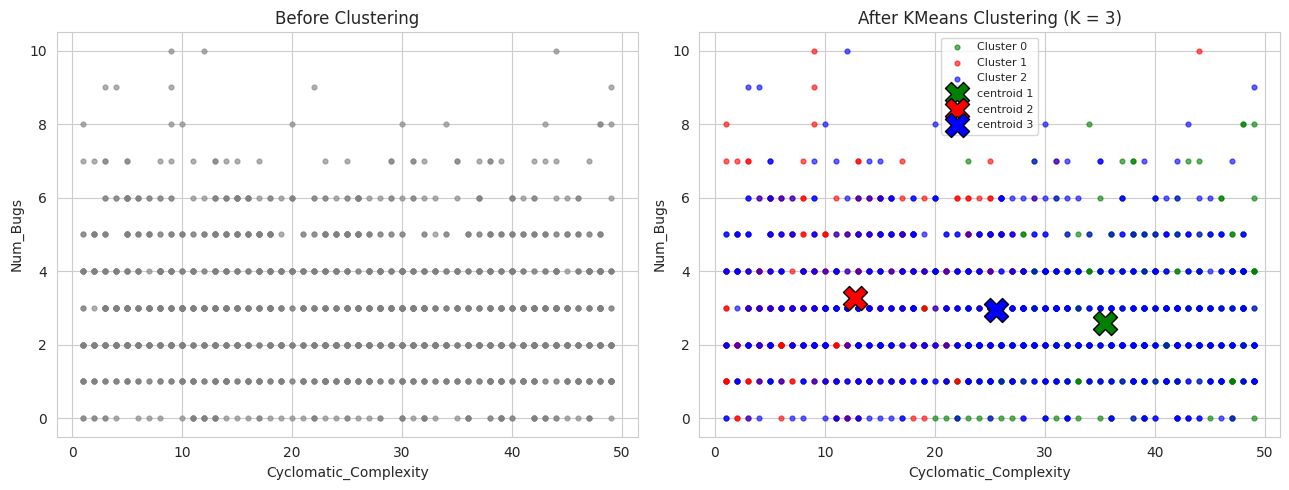

In [ ]:
# Showcase the clusters
plt.figure(figsize=(13, 5))
color = ['green', 'red', 'blue', 'purple', 'black', 'yellow']

plt.subplot(1, 2, 1)
plt.scatter(df['Cyclomatic_Complexity'], df['Num_Bugs'], color='grey', s=12, alpha=0.6)
plt.xlabel('Cyclomatic_Complexity')
plt.ylabel('Num_Bugs')
plt.title('Before Clustering')

plt.subplot(1, 2, 2)
for i in range(3):
    plt.scatter(df[df.Cluster == i]['Cyclomatic_Complexity'],
                df[df.Cluster == i]['Num_Bugs'],
                color=color[i], s=12, alpha=0.6, label=f'Cluster {i}')

# Put the centroids back into the original units so they can be plotted
centroids = StandardScaler().fit(X).inverse_transform(km.cluster_centers_)
centroids = pd.DataFrame(centroids, columns=X.columns)

for i in range(3):
    plt.scatter(centroids['Cyclomatic_Complexity'][i], centroids['Num_Bugs'][i],
                color=color[i], s=300, marker='X', edgecolor='black',
                label=f'centroid {i + 1}')

plt.xlabel('Cyclomatic_Complexity')
plt.ylabel('Num_Bugs')
plt.title('After KMeans Clustering (K = 3)')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()